In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
#from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
#upload dataset
data=pd.read_csv("/content/balance-scale.csv")
#Display the first five records
print("First five records:")
print(data.head())
print("Last few records")
print(data.tail())

First five records:
   class  left_weight  left_distance  right_weight  right_distance
0      1            1              1             1               1
1      2            1              1             1               2
2      2            1              1             1               3
3      2            1              1             1               4
4      2            1              1             1               5
Last few records
     class  left_weight  left_distance  right_weight  right_distance
620      0            5              5             5               1
621      0            5              5             5               2
622      0            5              5             5               3
623      0            5              5             5               4
624      1            5              5             5               5


In [ ]:
X=data.iloc[:,1:5]
Y=data.iloc[:,0]


In [ ]:
#Display the feature
print("\n Input features:")
print(X.head())
print("\n Target features:")
print(Y.head())


 Input features:
   left_weight  left_distance  right_weight  right_distance
0            1              1             1               1
1            1              1             1               2
2            1              1             1               3
3            1              1             1               4
4            1              1             1               5

 Target features:
0    1
1    2
2    2
3    2
4    2
Name: class, dtype: int64


In [ ]:
#Display the class distribution
class_count=Y.value_counts()
class_count

,count
class,
2,288
0,288
1,49


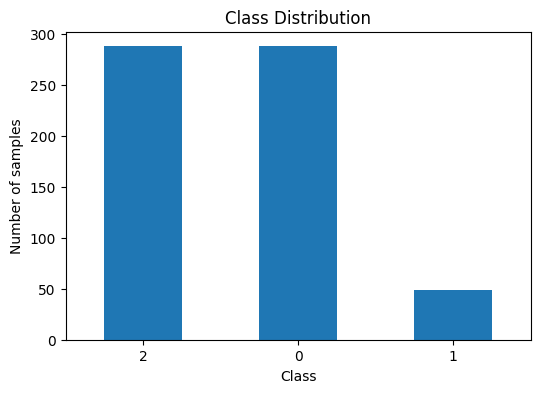

In [ ]:
plt.figure(figsize=(6,4))
class_count.plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.xticks(rotation=0)
plt.show()

In [ ]:
X_train,X_test,Y_train,Y_test=train_test_split(
    X,
    Y,
    test_size=0.3,
    random_state=42
    )

In [ ]:
model=DecisionTreeClassifier()
model.fit(X_train,Y_train)

DecisionTreeClassifier()

In [ ]:
print("\nClass Prior P(Ci):")
#print(model.class_prior_)



Class Prior P(Ci):


In [ ]:
#print(model.theta_)
#print(model.var_)

In [ ]:
y_pred=model.predict(X_test)
y_pred

array([1, 0, 0, 2, 0, 0, 2, 0, 0, 2, 0, 1, 0, 2, 0, 0, 2, 2, 2, 0, 1, 2,
       2, 0, 0, 0, 1, 0, 0, 0, 0, 2, 2, 0, 2, 0, 0, 0, 0, 1, 0, 2, 2, 0,
       2, 0, 0, 2, 0, 2, 0, 0, 2, 2, 0, 0, 0, 2, 0, 2, 0, 0, 2, 2, 0, 0,
       0, 2, 0, 0, 2, 2, 2, 2, 2, 0, 0, 2, 0, 0, 2, 0, 2, 0, 1, 0, 0, 2,
       2, 0, 0, 0, 2, 0, 0, 2, 2, 2, 2, 2, 0, 0, 1, 2, 0, 0, 0, 2, 2, 0,
       2, 1, 2, 2, 0, 2, 0, 0, 0, 1, 0, 2, 0, 2, 2, 2, 1, 2, 0, 2, 0, 0,
       0, 2, 0, 0, 0, 2, 0, 0, 0, 1, 2, 2, 1, 2, 2, 0, 2, 2, 2, 2, 2, 1,
       0, 2, 0, 0, 0, 0, 0, 2, 2, 1, 0, 0, 2, 0, 2, 2, 0, 2, 2, 2, 0, 0,
       0, 0, 2, 0, 2, 2, 0, 2, 0, 2, 2, 0])

In [ ]:
cm=confusion_matrix(Y_test,y_pred)
#accuracy,pression,recall,f1_score,auc
print(cm)

[[73  5  2]
 [14  0  4]
 [ 8  9 73]]


In [ ]:
accuracy=accuracy_score(Y_test,y_pred)
print(accuracy*100)

77.6595744680851


In [ ]:
print("\nClassification Report:")
print(classification_report(Y_test,y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.91      0.83        80
           1       0.00      0.00      0.00        18
           2       0.92      0.81      0.86        90

    accuracy                           0.78       188
   macro avg       0.56      0.57      0.57       188
weighted avg       0.77      0.78      0.77       188



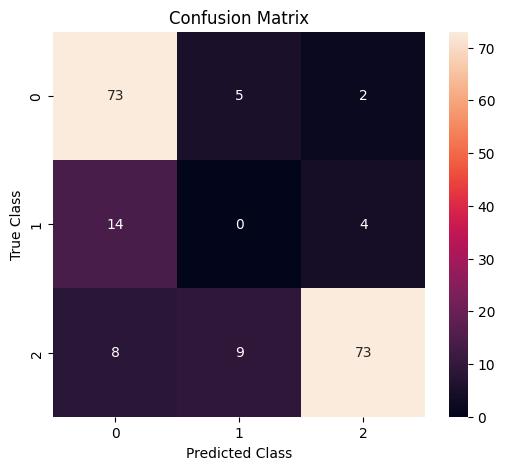

In [ ]:
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=model.classes_,
    yticklabels=model.classes_,


    )
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.show()